# Rule-Based Control Baseline

This notebook runs CityLearn's `BasicRBC` controller for one complete episode. The controller follows a fixed hourly schedule and does not learn from rewards. Its results provide a reference for later SAC and MARLISA experiments.

## BasicRBC rules

For the three action controls in the dataset, the default rules are:


| Time | DHW and electrical storage | Cooling device |
| --- | ---: | ---: |
| 22:00–08:00 | `+0.091` (charge) | `0.4` |
| 09:00–21:00 | `-0.08` (discharge) | `0.8` |

Storage and device constraints can reduce the action that is physically carried out. 

The general intention is to charge storage overnight, discharge during the day, and provide more cooling during daytime hours.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from run_rbc import run_basic_rbc

## Run one episode

The environment uses `central_agent=False`, giving each building a separate action vector. Results are saved under `outputs/rbc/`.

In [2]:
result = run_basic_rbc(
    schema=PROJECT_ROOT / "notebooks" / "data" / "schema.json",
    output_directory=PROJECT_ROOT / "outputs" / "rbc",
    random_seed=42,
)

control_steps = result["actions"]["time_step"].nunique()
print(f"Completed {control_steps} control steps.")
print(f"Results saved to: {result['output_directory']}")

Completed 719 control steps.
Results saved to: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment\outputs\rbc


## Inspect the actions

The following table and plot show the requested actions during the first 24 time steps.

,time_step,hour,building,action,value
0,0,1,Building_1,dhw_storage,0.091
1,0,1,Building_1,electrical_storage,0.091
2,0,1,Building_1,cooling_device,0.400
3,0,1,Building_2,dhw_storage,0.091
4,0,1,Building_2,electrical_storage,0.091
5,0,1,Building_2,cooling_device,0.400
6,0,1,Building_3,dhw_storage,0.091
7,0,1,Building_3,electrical_storage,0.091
8,0,1,Building_3,cooling_device,0.400
9,1,2,Building_1,dhw_storage,0.091


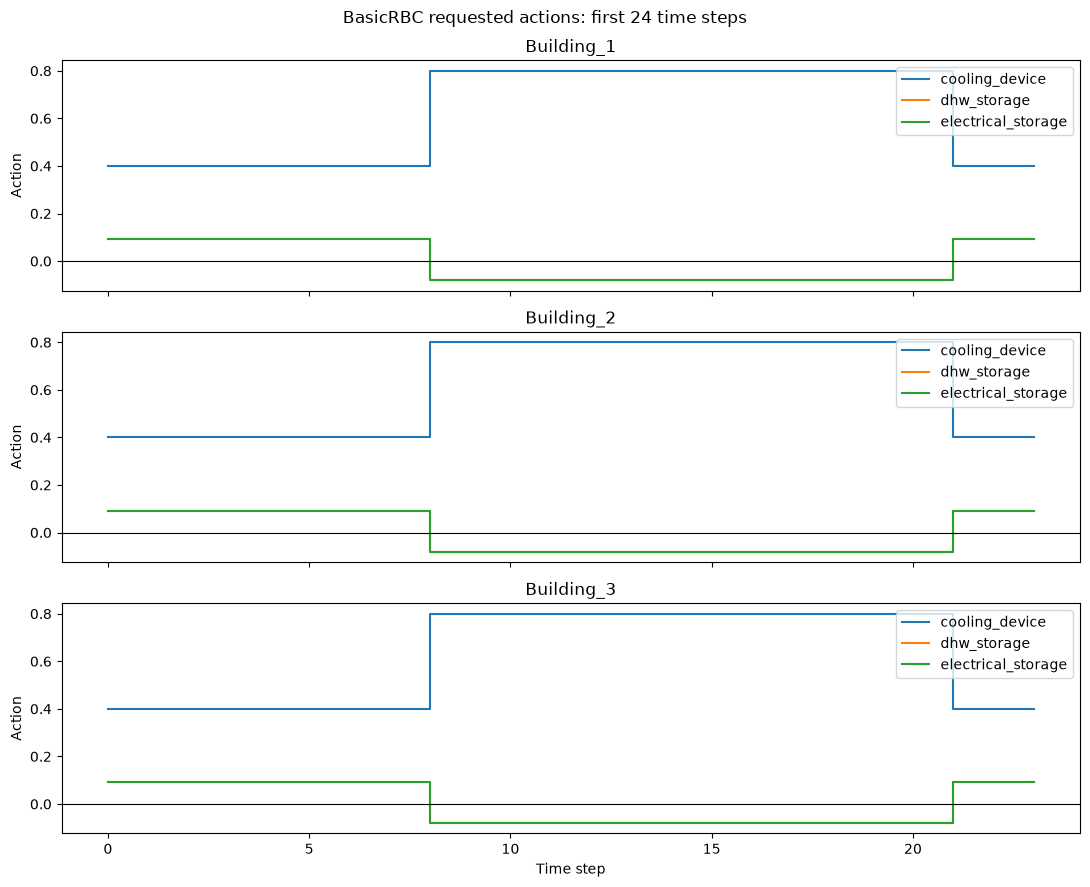

In [3]:
actions = result["actions"]
first_day = actions.loc[actions["time_step"] < 24]

display(first_day.head(12))

figure, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for axis, (building, data) in zip(axes, first_day.groupby("building")):
    for action_name, action_data in data.groupby("action"):
        axis.step(
            action_data["time_step"],
            action_data["value"],
            where="post",
            label=action_name,
        )
    axis.axhline(0.0, color="black", linewidth=0.8)
    axis.set_title(building)
    axis.set_ylabel("Action")
    axis.legend(loc="upper right")

axes[-1].set_xlabel("Time step")
figure.suptitle("BasicRBC requested actions: first 24 time steps")
figure.tight_layout()
plt.show()

## Evaluate the controller

For the ratio-based KPIs, `1.0` means equal to CityLearn's built-in baseline, values below `1.0` are improvements, and values above `1.0` are worse. Discomfort values are direct measurements and should be interpreted separately.

In [4]:
kpi_table = result["kpi_table"].round(3)
display(kpi_table.dropna(how="all"))

name,Building_1,Building_2,Building_3,District
cost_function,,,,
all_time_peak_average,NaN,NaN,NaN,1.089
annual_normalized_unserved_energy_total,0.018,0.017,0.017,0.017
carbon_emissions_total,1.998,1.936,1.735,1.890
cost_total,1.934,1.882,1.712,1.843
daily_one_minus_load_factor_average,NaN,NaN,NaN,0.708
daily_peak_average,NaN,NaN,NaN,1.329
discomfort_cold_delta_average,9.809,3.369,3.125,5.434
discomfort_cold_delta_maximum,13.638,9.427,5.148,9.404
discomfort_cold_delta_minimum,0.000,0.000,0.000,0.000


Note: 4 Main KPIs to monitor:
-  `carbon_emissions_total`: Does the agent reduce emissions? Show the actual emissions for the evaluation period and percentage improvement over BasicRBA
- `discomfort_proportion`: How often are occupants uncomfortable across buildings? Use each building's `discomfort_proportion`, then average them
- Worst-Building Discomfort: Is one building experiencing particularly poor comfort? Take the max building `discomfort_proportion`
- Discomfort gap: How unevenly is dicomfort distributed? Max minus Min building `discomfort_proportion`


Lower is better for these 4 metrics

Other supporting metrics:
- Grid electricity imports: `electricity_consumption_total`: Helps explain whether carbon reductions come form reducing imports or shifting them to cleaner hours
- Average daily peak: `daily_peak_average`: Checks whether coordinated control reduces peaks or create sync charging spikes

In [ ]:
selected_metrics = [
    "carbon_emissions_total",
    "cost_total",
    "electricity_consumption_total", #
    "daily_peak_average",
    "ramping_average",
    "discomfort_proportion",
]

available_metrics = [metric for metric in selected_metrics if metric in kpi_table.index]
display(kpi_table.loc[available_metrics])

name,Building_1,Building_2,Building_3,District
cost_function,,,,
carbon_emissions_total,1.998,1.936,1.735,1.890
cost_total,1.934,1.882,1.712,1.843
electricity_consumption_total,1.994,1.961,1.745,1.900
daily_peak_average,NaN,NaN,NaN,1.329
ramping_average,NaN,NaN,NaN,0.924
discomfort_proportion,0.975,0.908,0.957,0.947
